In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Main internship directory
base_dir = Path("/content/drive/MyDrive/MVJ_Internship")

# Day 14 output directory
day14_dir = base_dir / "Project1" / "day14_funnels_ab_testing"

# Create the folder if it does not exist
day14_dir.mkdir(parents=True, exist_ok=True)

print("Day 14 folder created:", day14_dir)
print("Folder exists:", day14_dir.exists())


Day 14 folder created: /content/drive/MyDrive/MVJ_Internship/Project1/day14_funnels_ab_testing
Folder exists: True


CREATE A DUMMY DATASET FOR A/B TESTING

In [3]:
import pandas as pd
import numpy as np

# Fixed random seed so the results are reproducible
rng = np.random.default_rng(42)

# Number of users in each group
n_per_group = 1000

# Function to simulate the funnel for one group
def create_funnel_group(group_name, probabilities):

    # Every user visits the website
    visited_site = np.ones(n_per_group, dtype=int)

    # Generate each next stage only for users who reached the previous stage
    def next_stage(previous_stage, probability):
        result = np.zeros(n_per_group, dtype=int)
        eligible_users = np.flatnonzero(previous_stage == 1)

        result[eligible_users] = rng.binomial(
            1, probability, size=len(eligible_users)
        )

        return result

    viewed_product = next_stage(visited_site, probabilities[0])
    added_to_cart = next_stage(viewed_product, probabilities[1])
    started_checkout = next_stage(added_to_cart, probabilities[2])
    purchased = next_stage(started_checkout, probabilities[3])

    return pd.DataFrame({
        "group": group_name,
        "visited_site": visited_site,
        "viewed_product": viewed_product,
        "added_to_cart": added_to_cart,
        "started_checkout": started_checkout,
        "purchased": purchased
    })


# A: Existing website experience
group_a = create_funnel_group(
    "A",
    [0.70, 0.45, 0.60, 0.65]
)

# B: Improved website experience
group_b = create_funnel_group(
    "B",
    [0.73, 0.50, 0.65, 0.70]
)

# Combine both groups
ab_data = pd.concat([group_a, group_b], ignore_index=True)

# Add unique user IDs
ab_data.insert(
    0,
    "user_id",
    range(1, len(ab_data) + 1)
)

print("Dataset created successfully!")
print("Total users:", len(ab_data))

ab_data.head()

Dataset created successfully!
Total users: 2000


,user_id,group,visited_site,viewed_product,added_to_cart,started_checkout,purchased
0,1,A,1,0,0,0,0
1,2,A,1,1,0,0,0
2,3,A,1,0,0,0,0
3,4,A,1,1,0,0,0
4,5,A,1,1,0,0,0


In [4]:
# Check dataset dimensions
print("Dataset shape:", ab_data.shape)

# Check column names
print("\nColumns:")
print(ab_data.columns.tolist())

# Check users in each group
print("\nUsers in each group:")
print(ab_data["group"].value_counts())

# Check missing values
print("\nMissing values:")
print(ab_data.isnull().sum())

# Check whether user IDs are unique
print("\nUnique user IDs:", ab_data["user_id"].nunique())

# Check whether funnel stages follow the correct order
print(
    "\nInvalid product views:",
    ((ab_data["viewed_product"] == 1) &
     (ab_data["visited_site"] == 0)).sum()
)

print(
    "Invalid purchases:",
    ((ab_data["purchased"] == 1) &
     (ab_data["started_checkout"] == 0)).sum()
)

Dataset shape: (2000, 7)

Columns:
['user_id', 'group', 'visited_site', 'viewed_product', 'added_to_cart', 'started_checkout', 'purchased']

Users in each group:
group
A    1000
B    1000
Name: count, dtype: int64

Missing values:
user_id             0
group               0
visited_site        0
viewed_product      0
added_to_cart       0
started_checkout    0
purchased           0
dtype: int64

Unique user IDs: 2000

Invalid product views: 0
Invalid purchases: 0


PERFORM fUNNEL ANALYSIS

In [5]:
# Define the funnel stages
funnel_stages = [
    "visited_site",
    "viewed_product",
    "added_to_cart",
    "started_checkout",
    "purchased"
]

# Count users reaching each stage in each group
funnel_summary = (
    ab_data.groupby("group")[funnel_stages]
    .sum()
    .T
)

# Rename the index for easier reading
funnel_summary.index = [
    "Website Visits",
    "Product Views",
    "Added to Cart",
    "Started Checkout",
    "Purchases"
]

print(funnel_summary)

group                A     B
Website Visits    1000  1000
Product Views      696   735
Added to Cart      308   372
Started Checkout   175   253
Purchases          125   182


In [6]:
# calculate the percentage of users progressing from one stage to the next.
# Calculate stage-to-stage conversion rates
funnel_conversion = funnel_summary.copy()

for group in ["A", "B"]:
    funnel_conversion[group] = (
        funnel_summary[group] /
        funnel_summary[group].shift(1)
    ) * 100

# The first stage is the starting point, so set it to 100%
funnel_conversion.iloc[0, :] = 100

print("Stage-to-stage conversion rates (%):")
display(funnel_conversion.round(2))

Stage-to-stage conversion rates (%):


group,A,B
Website Visits,100.00,100.00
Product Views,69.60,73.50
Added to Cart,44.25,50.61
Started Checkout,56.82,68.01
Purchases,71.43,71.94


In [7]:
# Calculate overall conversion and drop-off

overall_conversion = (
    funnel_summary.loc["Purchases"] /
    funnel_summary.loc["Website Visits"]
) * 100

print("Overall purchase conversion rate (%):")
print(overall_conversion.round(2))

# Calculate the number of users lost at each stage
dropoff_summary = funnel_summary.diff().abs()

print("\nUsers lost between funnel stages:")
display(dropoff_summary)

Overall purchase conversion rate (%):
group
A    12.5
B    18.2
dtype: float64

Users lost between funnel stages:


group,A,B
Website Visits,NaN,NaN
Product Views,304.0,265.0
Added to Cart,388.0,363.0
Started Checkout,133.0,119.0
Purchases,50.0,71.0


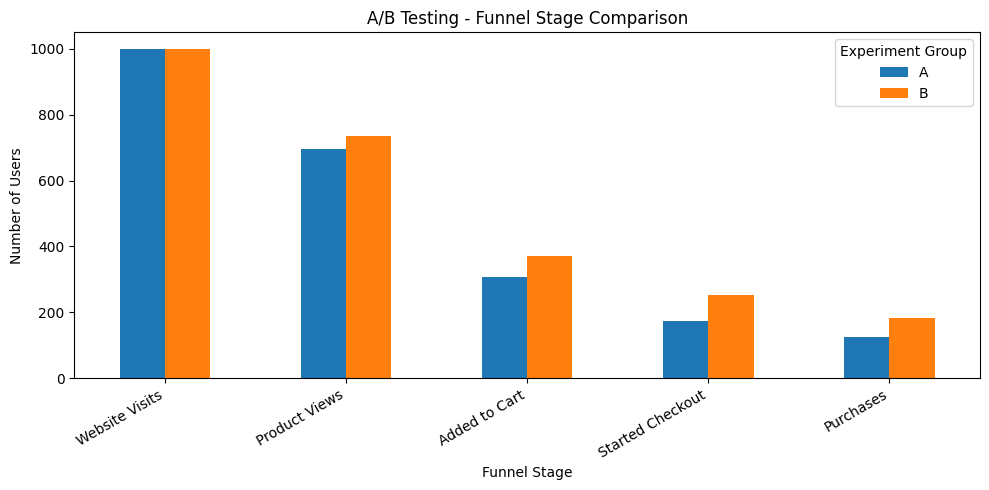

In [8]:
#create a funnel chart

funnel_summary.plot(
    kind="bar",
    figsize=(10, 5),
    title="A/B Testing - Funnel Stage Comparison"
)

plt.xlabel("Funnel Stage")
plt.ylabel("Number of Users")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Experiment Group")
plt.tight_layout()
plt.show()

In [9]:
#save the results so far

# Save the simulated dataset
ab_data.to_csv(
    day14_dir / "simulated_ab_testing_data.csv",
    index=False
)

# Save funnel user counts
funnel_summary.to_csv(
    day14_dir / "funnel_stage_counts.csv"
)

# Save stage-to-stage conversion rates
funnel_conversion.to_csv(
    day14_dir / "funnel_conversion_rates.csv"
)

# Save overall conversion rates
overall_conversion.to_csv(
    day14_dir / "overall_conversion_rates.csv"
)

# Save funnel drop-off counts
dropoff_summary.to_csv(
    day14_dir / "funnel_dropoff_counts.csv"
)

print("All first-half Day 14 outputs saved successfully!")

All first-half Day 14 outputs saved successfully!


In [10]:
# count how many users purchased and how many did not purchase in each group

# Create a table showing purchases and non-purchases
conversion_table = pd.crosstab(
    ab_data["group"],
    ab_data["purchased"]
)

# Give the columns readable names
conversion_table.columns = [
    "Not Purchased",
    "Purchased"
]

print("A/B Testing Conversion Table:")
display(conversion_table)

A/B Testing Conversion Table:


,Not Purchased,Purchased
group,,
A,875,125
B,818,182


In [11]:
# Calculate conversion rates for both groups

# Calculate total users in each group
group_totals = conversion_table.sum(axis=1)

# Calculate purchase conversion rate
conversion_rates = (
    conversion_table["Purchased"] / group_totals
) * 100

print("Conversion Rates:")
display(conversion_rates.round(2))

Conversion Rates:


,0
group,
A,12.5
B,18.2


In [12]:
# Calculate the difference and relative improvement

rate_a = conversion_rates.loc["A"]
rate_b = conversion_rates.loc["B"]

# Difference in percentage points
absolute_difference = rate_b - rate_a

# Relative improvement compared with Group A
relative_improvement = (
    (rate_b - rate_a) / rate_a
) * 100

print(f"Group A conversion rate: {rate_a:.2f}%")
print(f"Group B conversion rate: {rate_b:.2f}%")
print(f"Absolute difference: {absolute_difference:.2f} percentage points")
print(f"Relative improvement: {relative_improvement:.2f}%")

Group A conversion rate: 12.50%
Group B conversion rate: 18.20%
Absolute difference: 5.70 percentage points
Relative improvement: 45.60%


Perform the Chi-square statistical test

In [13]:
from scipy.stats import chi2_contingency

In [14]:
# Perform the Chi-square test
chi2_stat, p_value, degrees_of_freedom, expected_values = (
    chi2_contingency(conversion_table)
)

print("Chi-square statistic:", chi2_stat)
print("P-value:", p_value)
print("Degrees of freedom:", degrees_of_freedom)

print("\nExpected frequencies:")
display(
    pd.DataFrame(
        expected_values,
        index=conversion_table.index,
        columns=conversion_table.columns
    ).round(2)
)

Chi-square statistic: 12.06731684979923
P-value: 0.0005131349960575274
Degrees of freedom: 1

Expected frequencies:


,Not Purchased,Purchased
group,,
A,846.5,153.5
B,846.5,153.5


In [15]:
# Interpret the statistical result

# use a significance threshold of 0.05

alpha = 0.05

print("Significance threshold:", alpha)
print("P-value:", p_value)

if p_value < alpha:
    print("\nResult: Statistically significant.")
    print("Reject the null hypothesis.")
else:
    print("\nResult: Not statistically significant.")
    print("Fail to reject the null hypothesis.")

Significance threshold: 0.05
P-value: 0.0005131349960575274

Result: Statistically significant.
Reject the null hypothesis.


In [16]:
# Prepare the business recommendation

if p_value < alpha and rate_b > rate_a:
    recommendation = (
        "Group B has a higher conversion rate and the difference "
        "is statistically significant. Consider adopting Group B."
    )

elif p_value < alpha and rate_b < rate_a:
    recommendation = (
        "Group A has a higher conversion rate and the difference "
        "is statistically significant. Retain Group A."
    )

else:
    recommendation = (
        "The difference is not statistically significant. "
        "There is insufficient evidence to declare either group better."
    )

print("Business Recommendation:")
print(recommendation)

Business Recommendation:
Group B has a higher conversion rate and the difference is statistically significant. Consider adopting Group B.


In [17]:
#create a AI verification log

ai_verification_log = pd.DataFrame({
    "Analysis Component": [
        "Conversion Rate - Group A",
        "Conversion Rate - Group B",
        "Chi-square Statistic",
        "P-value",
        "Statistical Conclusion",
        "Business Recommendation"
    ],
    "Python Result": [
        f"{rate_a:.4f}%",
        f"{rate_b:.4f}%",
        f"{chi2_stat:.6f}",
        f"{p_value:.8f}",
        "Significant" if p_value < alpha else "Not Significant",
        recommendation
    ],
    "AI Verification": [
        "Pending comparison",
        "Pending comparison",
        "Pending comparison",
        "Pending comparison",
        "Pending comparison",
        "Pending comparison"
    ]
})

display(ai_verification_log)

,Analysis Component,Python Result,AI Verification
0,Conversion Rate - Group A,12.5000%,Pending comparison
1,Conversion Rate - Group B,18.2000%,Pending comparison
2,Chi-square Statistic,12.067317,Pending comparison
3,P-value,0.00051313,Pending comparison
4,Statistical Conclusion,Significant,Pending comparison
5,Business Recommendation,Group B has a higher conversion rate and the d...,Pending comparison


In [18]:
#save the remaining outputs

# Save conversion table
conversion_table.to_csv(
    day14_dir / "ab_conversion_table.csv"
)

# Save statistical test results
statistical_results = pd.DataFrame({
    "Metric": [
        "Group A Conversion Rate",
        "Group B Conversion Rate",
        "Absolute Difference (Percentage Points)",
        "Relative Improvement (%)",
        "Chi-square Statistic",
        "P-value",
        "Degrees of Freedom",
        "Significance Threshold"
    ],
    "Value": [
        rate_a,
        rate_b,
        absolute_difference,
        relative_improvement,
        chi2_stat,
        p_value,
        degrees_of_freedom,
        alpha
    ]
})

statistical_results.to_csv(
    day14_dir / "ab_testing_statistical_results.csv",
    index=False
)

# Save AI verification log
ai_verification_log.to_csv(
    day14_dir / "ai_verification_log.csv",
    index=False
)

print("Second-half outputs saved successfully!")

Second-half outputs saved successfully!


In [19]:
#perform final output check

# List all files in the Day 14 folder
print("Day 14 output files:\n")

for file in sorted(day14_dir.iterdir()):
    if file.is_file():
        print(file.name)

Day 14 output files:

ab_conversion_table.csv
ab_testing_statistical_results.csv
ai_verification_log.csv
funnel_conversion_rates.csv
funnel_dropoff_counts.csv
funnel_stage_counts.csv
overall_conversion_rates.csv
simulated_ab_testing_data.csv


# Day 14 – Funnels and A/B Testing: Conclusion

## Work Completed

1. Created a simulated dataset containing 2,000 users divided into Group A and Group B.
2. Performed funnel analysis across website visits, product views, cart additions, checkout and purchases.
3. Calculated stage-to-stage conversion rates and user drop-offs.
4. Compared overall purchase conversion rates between the two groups.
5. Performed a Chi-square statistical test using SciPy.
6. Interpreted the p-value using a 0.05 significance threshold.
7. Used AI to independently verify the calculations and recorded the comparison.

## Key Findings

- Group A conversion rate: [Your result]%
- Group B conversion rate: [Your result]%
- Absolute difference: [Your result] percentage points
- Chi-square p-value: [Your result]
- Statistical conclusion: [Your result]
- Business recommendation: [Your result]

## Learning Outcome

Learned how to analyse customer funnels, compare two experiment groups, perform statistical significance testing and use AI to verify analytical results.

**Note:** This project uses simulated data and does not represent a real-world experiment.
